In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import keras
import tensorflow as tf

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
count = 0
for dirname, _, filenames in os.walk('/kaggle/input'):
    count +=1
#     print(dirname)
#     for filename in filenames:
#         print(os.path.join(dirname, filename))
#         continue
print('Count:', count)

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

2024-04-22 21:44:58.721863: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-04-22 21:44:58.721955: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-04-22 21:44:58.839620: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


Count: 341


In [2]:
print(tf.__version__)
print(keras.__version__)
import sys
print("Python version:", sys.version)

2.15.0
3.2.1
Python version: 3.10.13 | packaged by conda-forge | (main, Dec 23 2023, 15:36:39) [GCC 12.3.0]


## Global Perameteres

In [3]:
FAST_RUN = False
IMAGE_WIDTH=224
IMAGE_HEIGHT=224
IMAGE_SIZE=(IMAGE_WIDTH, IMAGE_HEIGHT)
IMAGE_CHANNELS=3
batch_size = 128

## Loading the Images

Here we are defining a function, Read_Images, with the purpose of loading in the data from 70-dog-breeds-image-data-set. The function defines an empty list to store tuples of the filename, and the folder name that file was found showing the breed of the dog in the image. This is then put into a dataframe and returned. We will use this function to create our train, test, and validation data frames.

In [4]:
import os
import pandas as pd

# Define the directory path
base_dir = '../input/70-dog-breedsimage-data-set/'

# Define the directory names for test, train, and validation sets
test_dir = os.path.join(base_dir, 'test/')
train_dir = os.path.join(base_dir, 'train/')
val_dir = os.path.join(base_dir, 'valid/')

def Read_Images(image_path):
    # Initialize an empty list to store tuples of (filename, breed_type)
    file_info = []

    # Iterate through each directory (breed type) in the base directory
    for breed_type in os.listdir(image_path):
        # Construct the full path of the breed directory
        breed_dir = os.path.join(image_path, breed_type)

        # Check if the directory exists and is indeed a directory
        if os.path.isdir(breed_dir):
            # Iterate through each file in the breed directory
            for filename in os.listdir(breed_dir):
#                 print('filename:', filename)
#                 print('breedDir:', breed_dir)
                # Append only breed and filename, separated by a slash
                file_info.append((f"{breed_type}/{filename}", breed_type))  # Modified line

    # Create a DataFrame from the list of tuples
    df = pd.DataFrame(file_info, columns=['filename', 'breed'])

    # Display the DataFrame
    # print(df)
    return df

train_df = Read_Images(train_dir)
test_df = Read_Images(test_dir)
val_df = Read_Images(val_dir)

train_df

,filename,breed
0,Cocker/029.jpg,Cocker
1,Cocker/014.jpg,Cocker
2,Cocker/109.jpg,Cocker
3,Cocker/034.jpg,Cocker
4,Cocker/024.jpg,Cocker
...,...,...
7941,Corgi/053.jpg,Corgi
7942,Corgi/013.jpg,Corgi
7943,Corgi/016.jpg,Corgi
7944,Corgi/044.jpg,Corgi


### Label encoding the breed label

We will then convert the breed names in the DataFrame column 'breed' into numerical labels using a LabelEncoder. This assigns a unique number to each breed. It then creates one-hot encoded vectors from those numerical labels. One-hot encoding represents each breed with a binary vector where a single value of 1 indicates the specific breed. The code adds a new column 'breed_encoded_one_hot' to the DataFrame, containing those one-hot encoded vectors.

In [5]:
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical

# Use LabelEncoder to convert breed strings to numerical labels
label_encoder = LabelEncoder()
train_df['breed_encoded'] = label_encoder.fit_transform(train_df['breed'])


# Convert numerical labels to one-hot encoded vectors
num_classes = len(label_encoder.classes_)
breed_names = label_encoder.classes_

breed_encoded_labels = train_df['breed_encoded'].values  # Use .values to extract the underlying NumPy array

# Convert numerical labels to one-hot encoded vectors
breed_encoded_one_hot = to_categorical(breed_encoded_labels, num_classes=num_classes)

# Assign the one-hot encoded vectors to a new DataFrame column
train_df['breed_encoded_one_hot'] = list(breed_encoded_one_hot)  # Convert ndarray to list for assignment

print(train_df.head(3))


         filename   breed  breed_encoded  \
0  Cocker/029.jpg  Cocker             27   
1  Cocker/014.jpg  Cocker             27   
2  Cocker/109.jpg  Cocker             27   

                               breed_encoded_one_hot  
0  [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...  
1  [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...  
2  [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...  


In [6]:
print('The number of classes is:', len(label_encoder.classes_))

The number of classes is: 70


### DenseNet Setup

#### Resnet Preprocess script

In [7]:
import tensorflow as tf
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.image import ImageDataGenerator

def densenet_preprocess(img):
    img = img.astype('float32') 
  # Rescale image pixel values to the range [0, 1] (commonly used for ResNet)
    img = img.astype('float32') / 255.0

  # Center crop the image (might be specific to some ResNet variants)
#     if img.shape[0] > 224 and img.shape[1] > 224:
#         x_center = img.shape[0] // 2
#         y_center = img.shape[1] // 2
#         img = img[x_center - 112:x_center + 112, y_center - 112:y_center + 112]

  # Alternatively, resize the image to the expected input size (224x224 for most ResNets)
    img = tf.image.resize(img, (224, 224))

  # Optional: Apply data augmentation techniques (e.g., random cropping, flipping)
  # ... (Your data augmentation logic here)

  # Mean subtraction specific to ResNet (depends on the image channel order)
#     mean_vec = [0.485, 0.456, 0.406]  # BGR order (adjust for RGB if needed)
    mean_vec = [0.485, 0.456, 0.406] # Imagenet order
#     mean_vec = [0.4914, 0.4822, 0.4465] # CIFAR-10 does it this way
    img -= mean_vec
#     print(img.max(), img.min())  
    return img

In [8]:
# Alternative to cells above defining generators and datagens
test_datagen = ImageDataGenerator(
#     rescale=1./255,  # Rescale for consistency (already done in pre-processing)
    preprocessing_function=densenet_preprocess,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
)

train_datagen = ImageDataGenerator(
#     rescale=1./255,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    preprocessing_function=densenet_preprocess,
#     validation_split=0.2
)

val_datagen = ImageDataGenerator(
#     rescale=1./255,  # Rescale for consistency (already done in pre-processing)
    preprocessing_function=densenet_preprocess,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    
)



print('Below is test_gen')
# Define test generator
test_generator = test_datagen.flow_from_dataframe(
    test_df,
    directory=test_dir,
    x_col="filename",
    y_col="breed",
    target_size=(224, 224),
    batch_size=batch_size,
    class_mode='categorical'
)

print('\nBelow is train_gen')
train_generator = train_datagen.flow_from_dataframe(
    train_df,
    directory=train_dir,
    x_col="filename",
    y_col="breed",
    target_size=(224, 224),
    batch_size=batch_size,
#     class_mode='categorical',
    subset='training',  # Subset for training
    shuffle=True  # Shuffle training data
)

print('\nBelow is val_gen')
val_generator = val_datagen.flow_from_dataframe(
    val_df,
    directory=val_dir,
    x_col="filename",
    y_col="breed",
    target_size=(224, 224),
    batch_size=batch_size,
    class_mode='categorical',
#     subset='validation',  # Subset for validation
    shuffle=True  # No need to shuffle validation data
)

Below is test_gen


Found 700 validated image filenames belonging to 70 classes.



Below is train_gen


Found 7946 validated image filenames belonging to 70 classes.



Below is val_gen


Found 700 validated image filenames belonging to 70 classes.


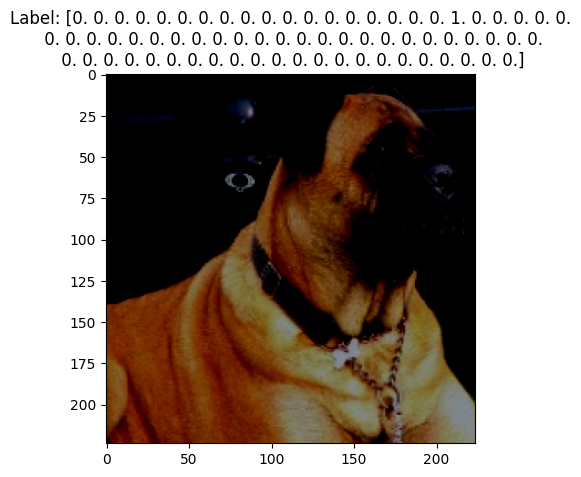

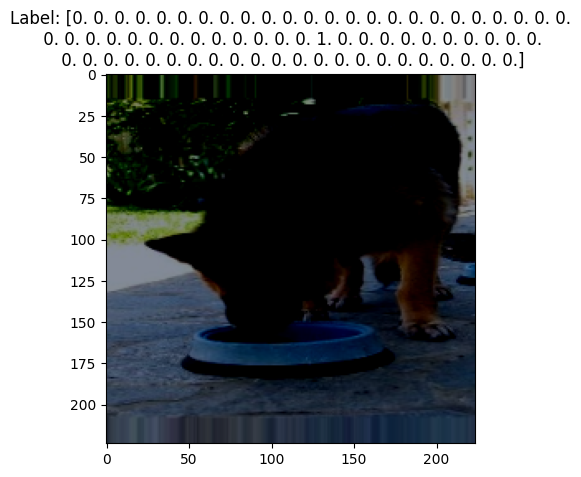

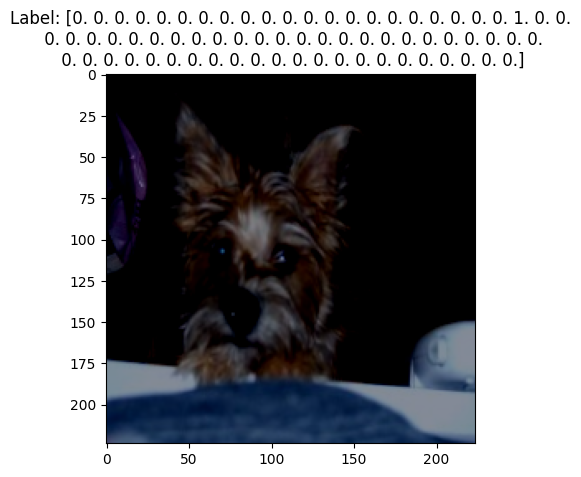

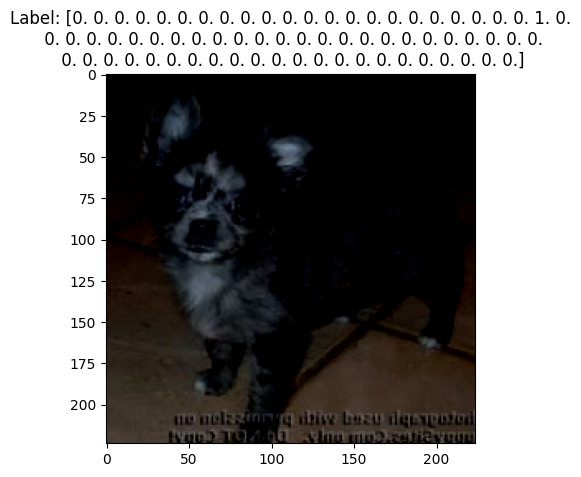

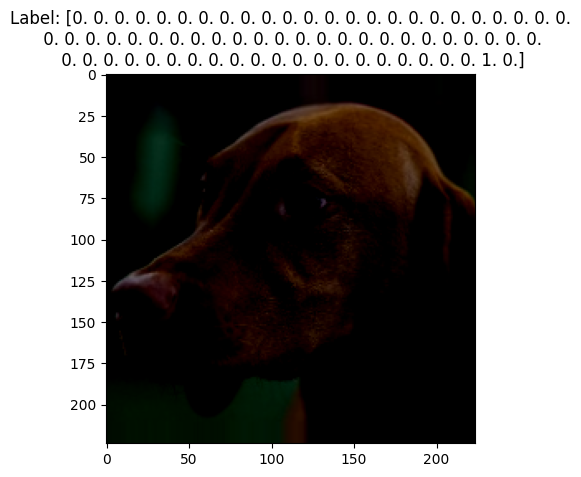

In [9]:
import matplotlib.pyplot as plt 

def plot_sample_images(generator, num_images=5):
    X_batch, y_batch = next(generator)  # Get a single batch

    for i in range(num_images):
        image = X_batch[i]
        label = y_batch[i] 
        # If necessary, apply any decoding of labels
#         label = np.argmax(predictions, axis=1)

        plt.figure()
        plt.imshow(image)
        plt.title(f"Label: {label}")
        plt.show()

plot_sample_images(train_generator)  # Visualize images after preprocessing and augmentation

# Model Loading

In [10]:
base_model = DenseNet121(weights='imagenet', include_top=False)

       0/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

 4202496/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

15867904/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [11]:
from tensorflow.keras import regularizers
l2_reg = regularizers.l2(0.001)  # .001 == weight decay value

In [12]:
from tensorflow.keras.regularizers import L1
# Add custom classification head
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(1024, activation='selu', kernel_regularizer=L1(l1=0.001))(x)
predictions = Dense(num_classes, activation='softmax')(x)

# Combine base model and custom head
model = Model(inputs=base_model.input, outputs=predictions)

# Freeze layers of the base model
# for layer in base_model.layers:
#     layer.trainable = False

# Compile the model
model.compile(optimizer=Adam(learning_rate=0.001), 
              loss='categorical_crossentropy',
              metrics=['accuracy'])

# Split the dataset into training and validation sets
# train_files, val_files, train_labels, val_labels = train_test_split(df['filename'], df['breed'], test_size=0.2, random_state=42)

checkpoint_path = "/kaggle/working/training_1/cp.ckpt.weights.h5"
checkpoint_dir = os.path.dirname(checkpoint_path)

# Create a callback that saves the model's weights
cp_callback = tf.keras.callbacks.ModelCheckpoint(filepath=checkpoint_path,
                                                 save_weights_only=True,
                                                 verbose=1)

early_stopping_callback = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',  # Monitor validation loss
    patience=3,           # Number of epochs with no improvement after which training will be stopped
    restore_best_weights=True  # Restore the weights from the epoch with the best validation loss
)

# # Unfreeze some layers for fine-tuning
# for layer in base_model.layers[-20:]:
#     layer.trainable = True

# # Recompile the model after unfreezing
# model.compile(optimizer=Adam(learning_rate=0.0001), 
#               loss='categorical_crossentropy',
#               metrics=['accuracy'])


### Compiling

In [13]:
model.compile(optimizer=Adam(learning_rate=0.0001, clipnorm=1.0), 
              loss='categorical_crossentropy',
              metrics=['accuracy'])

## Training

In [14]:
# Train the model
history = model.fit(train_generator, 
          epochs=10, 
          validation_data=val_generator,
          callbacks=[cp_callback,]
#                     early_stopping_callback],
#           compile_args={'kernel_regularizer': l2_reg},
         )


# model.fit_generator(
#     train_generator,
#     epochs=10, 
#     validation_data=val_generator,
#     steps_per_epoch=len(train_df), # batch_size  
#     validation_steps=len(val_df), # batch_size 
#     callbacks=[cp_callback,
#                     early_stopping_callback],
# )

Epoch 1/10


/opt/conda/lib/python3.10/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:120: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


I0000 00:00:1713822577.460344      66 device_compiler.h:186] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


 1/63 ━━━━━━━━━━━━━━━━━━━━ 4:08:44 241s/step - accuracy: 0.0078 - loss: 33.2013

 2/63 ━━━━━━━━━━━━━━━━━━━━ 38s 639ms/step - accuracy: 0.0078 - loss: 33.1326   

 3/63 ━━━━━━━━━━━━━━━━━━━━ 2:06 2s/step - accuracy: 0.0087 - loss: 33.0628  

... (652 outputs left out)

62/63 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.9946 - loss: 2.7417

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9946 - loss: 2.7386


Epoch 10: saving model to /kaggle/working/training_1/cp.ckpt.weights.h5


63/63 ━━━━━━━━━━━━━━━━━━━━ 172s 3s/step - accuracy: 0.9946 - loss: 2.7356 - val_accuracy: 0.9400 - val_loss: 2.4543


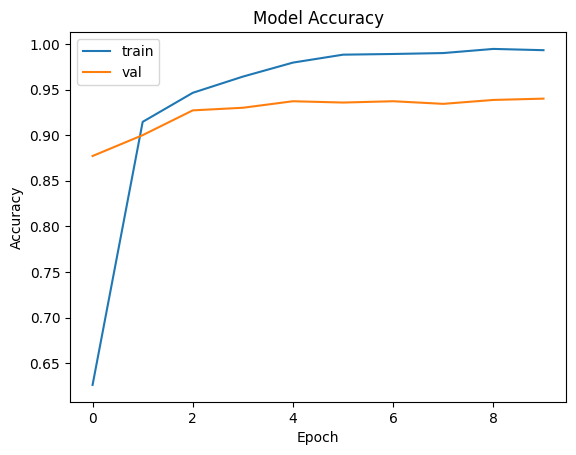

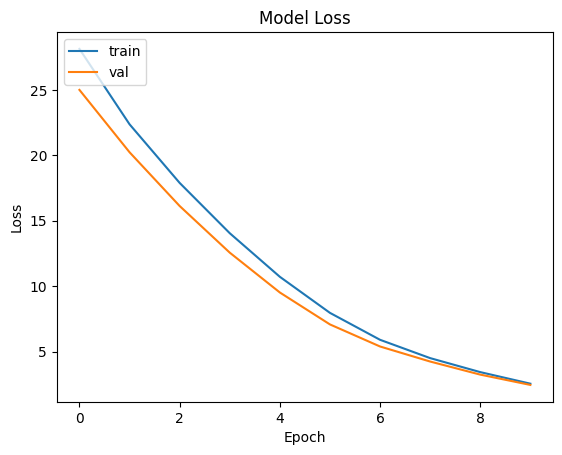

In [15]:
import matplotlib.pyplot as plt
# history = model.fit(train_generator, 
#          epochs=20, 
#          validation_data=val_generator,
#          callbacks=[cp_callback] 
#         )

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

# Similar plot for loss
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

In [16]:
from sklearn.metrics import confusion_matrix
import seaborn as sn 

y_pred = model.predict(val_generator)
y_pred_classes = np.argmax(y_pred, axis=1)

# Assuming your val_generator generates batches of (images, labels)
y_true = [] 
for X_batch, y_batch in val_generator:  
    y_true.extend(np.argmax(y_batch, axis=1))

# Creating the confusion matrix
cm = confusion_matrix(y_true, y_pred_classes)

plt.figure(figsize=(10, 8))  
sn.heatmap(cm, annot=True, fmt='d') 
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

1/6 ━━━━━━━━━━━━━━━━━━━━ 1:00 12s/step

2/6 ━━━━━━━━━━━━━━━━━━━━ 0s 130ms/step

3/6 ━━━━━━━━━━━━━━━━━━━━ 3s 1s/step   

4/6 ━━━━━━━━━━━━━━━━━━━━ 2s 1s/step

5/6 ━━━━━━━━━━━━━━━━━━━━ 1s 2s/step

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step

In [ ]:
loss, accuracy = model.evaluate(train_generator)
print("Train Accuracy:", accuracy)

loss, accuracy = model.evaluate(test_generator)
print("Test Accuracy:", accuracy)

In [ ]:
# Evaluate the model
loss, accuracy = model.evaluate(val_generator)
print("Validation Accuracy:", accuracy)

# Make predictions
predictions = model.predict(val_generator)
predictions

In [ ]:
# train_accuracy = round(model.history.history['accuracy'][-1], 3)
# val_accuracy = round(model.history.history['val_accuracy'][-1], 3)
# print('tr:',train_accuracy)
# print('val:',val_accuracy)
model.save(f'/kaggle/working/model_v5_densenet_{accuracy}.keras')
model.save(f'/kaggle/working/model_v5_densenet_{accuracy}.h5')

In [ ]:
predictions = model.predict(val_generator)

In [ ]:
# !zip /kaggle/working/
# print('dont sleep program')

In [ ]:
# Evaluate the model on the validation set
loss, accuracy = model.evaluate(val_generator)
print("Validation Loss:", loss)
print("Validation Accuracy:", accuracy)

# Alternatively, if you have a separate test dataset
# Evaluate the model on the test set
test_loss, test_accuracy = model.evaluate(test_generator)
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)


In [ ]:
from tensorflow.keras.preprocessing import image
import numpy as np

# Load and preprocess the single image

# Afgan Hound
# img_path = '/kaggle/input/120-dog-breeds-breed-classification/Images/n02088094-Afghan_hound/n02088094_10832.jpg'

# Bloodhound
img_path ='/kaggle/input/120-dog-breeds-breed-classification/Images/n02088466-bloodhound/n02088466_10506.jpg'

# Beagle
# img_path = '/kaggle/input/120-dog-breeds-breed-classification/Images/n02088364-beagle/n02088364_10108.jpg'  # Replace with the path to your image
img = image.load_img(img_path, target_size=(IMAGE_HEIGHT, IMAGE_WIDTH))
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)  # Add batch dimension
img_array /= 255.  # Normalize pixel values

# Make predictions
predictions = model.predict(img_array)

# Get predicted class labels
predicted_class = np.argmax(predictions, axis=1)

# Print the predicted class
print("Predicted Class:", predicted_class)

predicted_breeds = breed_names[predicted_class]  # Map indices to breed names
print('Predicted', predicted_breeds[0])

from IPython.display import Image

display(Image(filename=img_path))

## Testing the Data

    "My personal research and development philosophy (and hence the exercises in the book) have a strong emphasis on testing algorithms. It’s too easy in computer vision to develop analgorithm that does something plausible on a few images rather than something correct. The best way to validate your algorithms is to use a three-part strategy. First, test your algorithm on clean synthetic data, for which the exact results are known. Second, add noise to the data and evaluate how the performance degrades as a function of noise level. Finally, test the algorithm on real-world data, preferably drawn from a wide variety of sources, such as photos found on the web. Only then can you truly know if your algorithm can deal with real-world complexity, i.e., images that do not fit some simplified model or assumptions."

– Richard Szeliski

SZELISKI, RICHARD. Computer Vision: Algorithms and Applications. SPRINGER NATURE, 2023. 

First, test your algorithm on clean synthetic data

Second, add noise to the data and evaluate how the performance degrades as a function of noise level

Finally, test the algorithm on real-world data, preferably drawn from a wide variety of sources, such as photos found on the web. Only then can you truly know if your algorithm can deal with real-world complexity, i.e., images that do not fit some simplified model or assumptions."

In [ ]:
history = model.fit(train_generator, 
          epochs=50, 
          validation_data=val_generator,
          callbacks=[cp_callback,]
         )